# Generate observations configuration

Define the onshore wave observations available for the Samoa case (buoys, tide gauges, spectral sites, …), preview them on a map, and save a **GeoJSON** file compatible with QGIS and the HyGloW config loader.

Workflow:

1. Edit the `observations` dict below (one entry per instrument).
2. Run the preview cells to check the table and map.
3. Save the GeoJSON to disk.
4. If needed, update `"onshore_waves"` in `Samoa.json` to point to the saved file.

Schema follows `NorthCarolina/inputs/JennBuoys/JennBuoys_coordinates.json`:
each feature has `instrument_id`, `type`, `institution`, `recording`, and optional fields such as `depth`, `name`, or `msl`.

In [13]:
from utils import observations as obs
from utils import plotting as plot
from utils.config import PATHS, resolve

## Parameters

In [14]:
output_path = obs.geojson_path()

print(f"output   : {output_path}")
print(f"AoI      : {resolve(PATHS['aoi_file'])}")
print(f"topobathy: {resolve(PATHS['topobathy_file'])}")

output   : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/LauriBuoys/LauriBuoys_coordinates.json
AoI      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/AoI_Polygons/Samoa_AoI.shp
topobathy: /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_300m.tif


## Observations dict

Edit the dictionary below. Keys are unique `instrument_id` strings.

Required per entry:
- `lon`, `lat` — WGS84 coordinates
- `type` — role used downstream (`validation`, `waves`, `spectrum`, `calibration`, `levels`, `ignore`, …)
- `institution` — data provider (e.g. `IMOS`, `NDBC`, `SPREP`)
- `recording` — approximate coverage period as a string (e.g. `"2010-2024"`)

Optional:
- `depth` — water depth in metres (`null` if unknown)
- `name` — human-readable station name
- `role` — overrides `type` when filtering by role in later notebooks
- any extra property (e.g. `msl` for tide gauges) is kept in the GeoJSON

In [15]:
observations: dict[str, dict] = {
    # --- example entries: replace with your real stations ---
    "SAMOA_BUOY_01": {
        "lon": -172.20444,
        "lat": -13.87919,
        "type": "waves",
        "institution": "SPC",
        "recording": "2015-2024",
        "depth": -93.0,
        "name": "Savaii closest buoy",
    },
    "SAMOA_WAVE_01": {
        "lon": -170.51404,
        "lat": -14.25357,
        "type": "waves",
        "institution": "SPC",
        "recording": "2018-2024",
        "depth": -70.0,
        "name": "Ameican Samoa east buoy",
    },
}

## Build GeoJSON and preview table

In [16]:
feature_collection = obs.dict_to_geojson(observations)
preview_df = obs.geojson_to_dataframe(feature_collection)
preview_df

,type,institution,recording,depth,name,lon,lat
instrument_id,,,,,,,
SAMOA_BUOY_01,waves,SPC,2015-2024,-93.0,Savaii closest buoy,-172.20444,-13.87919
SAMOA_WAVE_01,waves,SPC,2018-2024,-70.0,Ameican Samoa east buoy,-170.51404,-14.25357


## Map

(<Figure size 900x700 with 2 Axes>,
 <Axes: title={'center': 'Samoa observations'}, xlabel='longitude', ylabel='latitude'>)

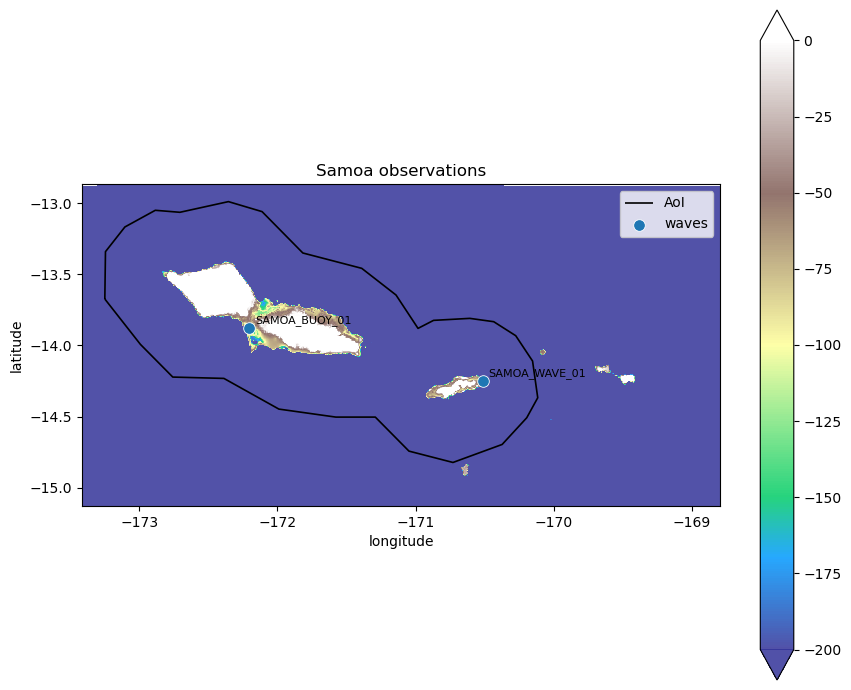

In [17]:
plot.plot_case_map(obs.dict_to_gdf(observations), title="Samoa observations")

## Save GeoJSON

In [18]:
obs.save_geojson(feature_collection, output_path)

print(f"Wrote {len(feature_collection['features'])} feature(s) to:\n  {output_path}")

Wrote 2 feature(s) to:
  /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/LauriBuoys/LauriBuoys_coordinates.json


## Samoa.json reference

The case config already points to the default output path:

```json
"onshore_waves": "inputs/LauriBuoys/LauriBuoys_coordinates.json"
```

Change this string only if you save the GeoJSON somewhere else.